# R16 · Contraste de la segmentación: DBSCAN y jerárquico

**Proyecto Final Integrador · Machine Learning I · Universidad EAN**
Integrantes: Claudia Naranjo, Yery Pedraza y Nicolás Ruiz.

¿La segmentación de R15 (K-means, k = 2) depende del algoritmo? Se contrasta con DBSCAN y con
agrupamiento jerárquico, con **la misma partición y la misma preparación** de R15. Se resume en
[`contraste_R16.md`](contraste_R16.md).

| Sección | Criterio de R16 |
|---|---|
| §1 Misma partición y preparación | Parámetros de cada algoritmo |
| §2 DBSCAN | Gráfico de k-distancias; sensibilidad a 5 valores de eps con grupos y % de ruido |
| §3 Jerárquico | Dendrogramas de dos enlaces; corte justificado con la altura de las fusiones |
| §4 Comparación | ARI y tablas cruzadas; qué reaparece y qué solo existe en uno |
| §5 Ruido y segmentos propios | Perfil con medianas |

**Confidencialidad:** solo cifras agregadas.

## 0. Configuración

In [1]:
import sys
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
import sklearn

RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "datos_crudos").is_dir())
sys.path.insert(0, str(RAIZ / "src"))

from cartera import datos
from cartera import segmentacion as sg
from cartera.config import SEMILLA

np.random.seed(SEMILLA)
print("Semilla", SEMILLA, "| Python", sys.version.split()[0], "| pandas", pd.__version__,
      "| numpy", np.__version__, "| scikit-learn", sklearn.__version__, "| scipy", scipy.__version__,
      "| matplotlib", matplotlib.__version__)

Matplotlib is building the font cache; this may take a moment.


Semilla 2026 | Python 3.14.7 | pandas 3.0.6 | numpy 2.5.3 | scikit-learn 1.9.1 | scipy 1.18.1 | matplotlib 3.11.2


## 1. Misma partición y preparación que R15

In [2]:
from sklearn.cluster import DBSCAN, KMeans
from sklearn.metrics import adjusted_rand_score, silhouette_score
from sklearn.neighbors import NearestNeighbors

saldos, movs = datos.leer_todo()
perfil = sg.perfil(saldos, movs)
ent, prueba = sg.particion(perfil, SEMILLA)
prep = sg.preparacion().fit(ent[sg.VARIABLES])
Z = prep.transform(ent[sg.VARIABLES])
kmeans = KMeans(sg.K, n_init=sg.N_INIT, random_state=SEMILLA).fit(Z)
# Se numera el grupo de K-means por su atraso mediano: 0 = paga a tiempo o casi, 1 = paga tarde
orden = np.argsort([np.median(ent.atraso_mediano.to_numpy()[kmeans.labels_ == g]) for g in range(sg.K)])
etq_km = np.argsort(orden)[kmeans.labels_]
nombres_km = {0: "paga a tiempo o casi", 1: "paga tarde"}
print("Entrenamiento:", len(ent), "clientes | K-means:", dict(zip(*np.unique(etq_km, return_counts=True))))

Entrenamiento: 158 clientes | K-means: {np.int64(0): np.int64(120), np.int64(1): np.int64(38)}


**Parámetros:**
- **K-means (R15):** k = 2, 50 reinicios, semilla 2026.
- **DBSCAN:** `min_samples = 8` (número de variables + 1, la regla usual) y `eps` elegido con el gráfico
  de k-distancias (§2). Distancia euclidiana en el espacio preparado.
- **Jerárquico:** enlaces de Ward y promedio, distancia euclidiana, sobre los 158 clientes de
  entrenamiento **sin submuestra** (son pocos), así que no necesita semilla. Corte por la altura de
  las fusiones (§3).

## 2. DBSCAN

**Gráfico de k-distancias:** para cada cliente, la distancia a su 8.º vecino más cercano, ordenada
de menor a mayor. El codo de la curva sugiere `eps`: a partir de ahí, las distancias crecen rápido y
los puntos quedan aislados.

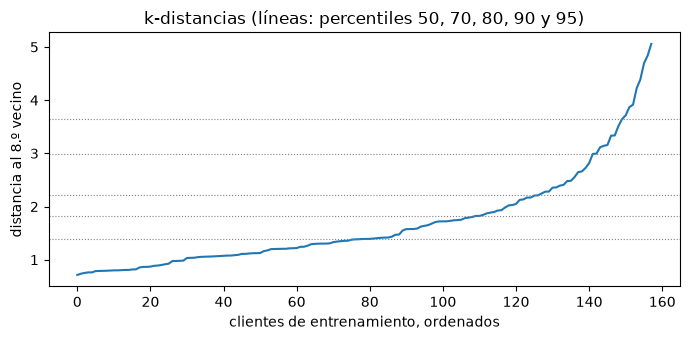

{50: 1.39, 70: 1.82, 80: 2.21, 90: 2.99, 95: 3.65}


In [3]:
MIN_SAMPLES = 8
dist, _ = NearestNeighbors(n_neighbors=MIN_SAMPLES).fit(Z).kneighbors(Z)
kdist = np.sort(dist[:, -1])
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(kdist)
for q in [50, 70, 80, 90, 95]:
    ax.axhline(np.percentile(kdist, q), ls=":", lw=0.8, color="gray")
ax.set_xlabel("clientes de entrenamiento, ordenados"); ax.set_ylabel(f"distancia al {MIN_SAMPLES}.º vecino")
ax.set_title("k-distancias (líneas: percentiles 50, 70, 80, 90 y 95)")
plt.tight_layout(); plt.show()
print({q: round(float(np.percentile(kdist, q)), 2) for q in [50, 70, 80, 90, 95]})

**Sensibilidad a eps.** Cinco valores, los percentiles 50, 70, 80, 90 y 95 de las k-distancias. La
silueta se calcula **sin el ruido**, y por eso siempre va junto al porcentaje de ruido.

In [4]:
filas = []
for q in [50, 70, 80, 90, 95]:
    eps = float(np.percentile(kdist, q))
    etq = DBSCAN(eps=eps, min_samples=MIN_SAMPLES).fit_predict(Z)
    no_ruido = etq != -1
    n_grupos = len(set(etq[no_ruido]))
    sil = silhouette_score(Z[no_ruido], etq[no_ruido]) if n_grupos >= 2 else np.nan
    filas.append({"percentil": q, "eps": eps, "grupos": n_grupos, "% ruido": (~no_ruido).mean() * 100,
                  "tamaños (sin ruido)": sorted(np.bincount(etq[no_ruido]).tolist(), reverse=True) if n_grupos else [],
                  "silueta sin ruido": sil})
sens = pd.DataFrame(filas).set_index("percentil")
sens.round(3)

,eps,grupos,% ruido,tamaños (sin ruido),silueta sin ruido
percentil,,,,,
50,1.391,1,36.076,[101],NaN
70,1.823,1,18.354,[129],NaN
80,2.209,1,10.759,[141],NaN
90,2.991,1,3.797,[152],NaN
95,3.654,1,0.633,[157],NaN


**eps elegido:** el percentil 90 de las k-distancias, en el codo de la curva. No se usa ninguna
etiqueta ni desenlace para elegirlo.

In [5]:
EPS = float(np.percentile(kdist, 90))
etq_db = DBSCAN(eps=EPS, min_samples=MIN_SAMPLES).fit_predict(Z)
print(f"eps = {EPS:.2f} | grupos: {len(set(etq_db) - {-1})} | ruido: {(etq_db == -1).mean() * 100:.1f} % "
      f"({(etq_db == -1).sum()} clientes)")

eps = 2.99 | grupos: 1 | ruido: 3.8 % (6 clientes)


## 3. Jerárquico: Ward y enlace promedio

Los dendrogramas muestran a qué altura se fusiona cada par de grupos. Un salto grande entre dos
fusiones seguidas indica que se están uniendo grupos muy distintos: ahí conviene cortar.

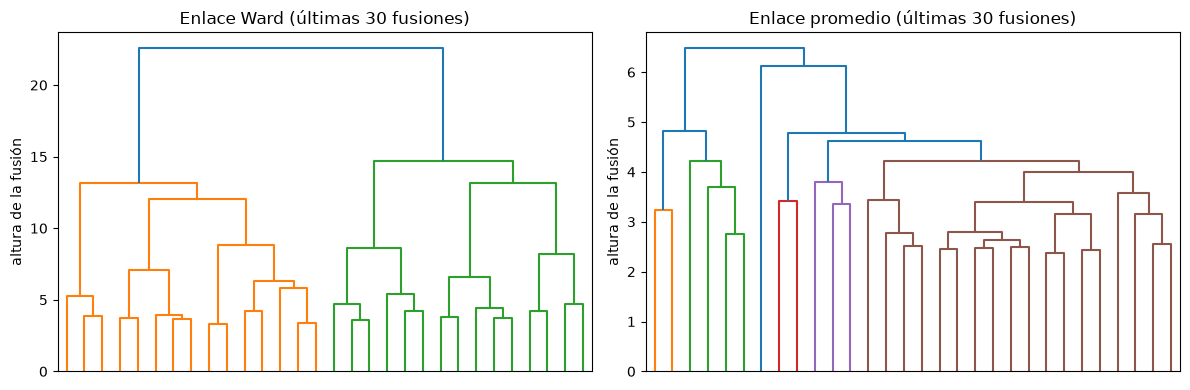

In [6]:
from scipy.cluster.hierarchy import dendrogram, fcluster, linkage

enlaces = {"Ward": linkage(Z, method="ward"), "promedio": linkage(Z, method="average")}
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, (nombre, L) in zip(axes, enlaces.items()):
    dendrogram(L, ax=ax, no_labels=True, color_threshold=None, truncate_mode="lastp", p=30)
    ax.set_title(f"Enlace {nombre} (últimas 30 fusiones)"); ax.set_ylabel("altura de la fusión")
plt.tight_layout(); plt.show()

In [7]:
alturas = pd.DataFrame({nombre: L[-8:, 2][::-1] for nombre, L in enlaces.items()},
                       index=[f"{i} grupos → {i - 1}" for i in range(2, 10)])
alturas["salto Ward"] = alturas["Ward"] - alturas["Ward"].shift(-1)
alturas["salto promedio"] = alturas["promedio"] - alturas["promedio"].shift(-1)
alturas.round(2)

,Ward,promedio,salto Ward,salto promedio
2 grupos → 1,22.56,6.47,7.89,0.34
3 grupos → 2,14.66,6.13,1.48,1.31
4 grupos → 3,13.18,4.82,0.03,0.05
5 grupos → 4,13.15,4.77,1.11,0.16
6 grupos → 5,12.04,4.61,3.23,0.39
7 grupos → 6,8.81,4.22,0.23,0.01
8 grupos → 7,8.58,4.21,0.40,0.22
9 grupos → 8,8.18,3.99,NaN,NaN


**Corte.** En Ward, el salto más grande de altura está en la última fusión (de 2 grupos a 1): cortar
ahí da **2 grupos**. En el enlace promedio, las últimas fusiones solo van sumando clientes aislados,
uno o pocos a la vez, al grupo principal: es el comportamiento típico de ese enlace con datos que no
forman grupos compactos. Se corta también en 2 para comparar al mismo nivel y se reporta el tamaño.

In [8]:
etq_ward = fcluster(enlaces["Ward"], t=2, criterion="maxclust") - 1
etq_prom = fcluster(enlaces["promedio"], t=2, criterion="maxclust") - 1
pd.DataFrame({"Ward": np.bincount(etq_ward), "promedio": np.bincount(etq_prom)}, index=["grupo A", "grupo B"])

,Ward,promedio
grupo A,109,7
grupo B,49,151


## 4. Comparación con K-means

**Índice de Rand ajustado (ARI):** 1 = misma partición; 0 = lo que daría el azar. Para DBSCAN, el
ruido cuenta como un grupo más.

In [9]:
pd.Series({
    "K-means frente a Ward": adjusted_rand_score(etq_km, etq_ward),
    "K-means frente a enlace promedio": adjusted_rand_score(etq_km, etq_prom),
    "K-means frente a DBSCAN (ruido como grupo)": adjusted_rand_score(etq_km, etq_db),
    "Ward frente a DBSCAN": adjusted_rand_score(etq_ward, etq_db),
}).round(3).to_frame("ARI")

,ARI
K-means frente a Ward,0.641
K-means frente a enlace promedio,0.187
K-means frente a DBSCAN (ruido como grupo),0.160
Ward frente a DBSCAN,0.096


In [10]:
def cruzada(otra, nombre):
    t = pd.crosstab(pd.Series(etq_km).map(nombres_km).rename("K-means"), pd.Series(otra).rename(nombre))
    return t

cruzada(etq_ward, "Ward")

Ward,0,1
K-means,,
paga a tiempo o casi,107,13
paga tarde,2,36


In [11]:
cruzada(etq_prom, "promedio")

promedio,0,1
K-means,,
paga a tiempo o casi,0,120
paga tarde,7,31


In [12]:
cruzada(np.where(etq_db == -1, "ruido", etq_db.astype(str)), "DBSCAN")

DBSCAN,0,ruido
K-means,,
paga a tiempo o casi,120,0
paga tarde,32,6


In [13]:
pd.Series({
    "Silueta de K-means (todos)": silhouette_score(Z, etq_km),
    "Silueta de Ward (todos)": silhouette_score(Z, etq_ward),
    "Silueta de DBSCAN sin ruido": (silhouette_score(Z[etq_db != -1], etq_db[etq_db != -1])
                                    if len(set(etq_db) - {-1}) >= 2 else np.nan),
    "% de ruido de DBSCAN": (etq_db == -1).mean() * 100,
}).round(3).to_frame("valor")

,valor
Silueta de K-means (todos),0.353
Silueta de Ward (todos),0.277
Silueta de DBSCAN sin ruido,NaN
% de ruido de DBSCAN,3.797


## 5. Perfil del ruido y de los segmentos propios de un algoritmo

Medianas en unidades originales.

In [14]:
grupos = {
    "K-means: paga a tiempo o casi": etq_km == 0,
    "K-means: paga tarde": etq_km == 1,
    "DBSCAN: ruido": etq_db == -1,
    "DBSCAN: no ruido": etq_db != -1,
    "Enlace promedio: grupo chico": etq_prom == np.argmin(np.bincount(etq_prom)),
}
t = pd.DataFrame({g: ent.loc[m, sg.VARIABLES].median() for g, m in grupos.items()}).T.round(1)
t["clientes"] = [int(m.sum()) for m in grupos.values()]
t

,atraso_mediano,atraso_iqr,pct_tardias,facturas_por_anio,log_monto_mediano,pct_varios_abonos,pct_cierre_nota,clientes
K-means: paga a tiempo o casi,9.0,14.0,10.4,13.1,14.9,0.0,7.1,120
K-means: paga tarde,51.5,50.0,81.3,12.7,15.2,2.4,11.8,38
DBSCAN: ruido,104.0,152.0,82.1,12.4,15.1,7.9,35.1,6
DBSCAN: no ruido,15.0,16.0,20.0,13.1,14.9,0.0,7.4,152
Enlace promedio: grupo chico,103.0,151.0,80.8,12.4,15.0,7.5,33.3,7
